# 3.5 Practical B: Simulating *MYD88* L265P & Clinical Mutations in OpenMM

In [**3.4 Practical A**](06-alphafold-clinical-variants.ipynb), we saw that AlphaFold predicts human MYD88's TIR domain to sub-ångström accuracy (`0.70 Å` vs `7L6W`), and that **AlphaMissense** flags the Waldenström Macroglobulinemia driver mutation ***MYD88* L265P (UniProt `L252P`)** as **`0.9974` (Likely Pathogenic)**.

Now let's bring that static AlphaFold prediction to life with **OpenMM Molecular Dynamics**! In this practical you will:
1. Map the **5 Å buried hydrophobic pocket** surrounding **Leu252** inside the MYD88 TIR domain (discovering that a second lymphoma hotspot, **Met219 / clinical M232T**, packs directly against it!).
2. Introduce **L252P (clinical L265P)** — or *any* other clinical MYD88 mutation — ***in silico***, add force-field hydrogens with `OpenMM Modeller`, and run a **live energy minimisation & MD relaxation** on the server.
3. Analyse **50 ps WT vs. L252P MYD88 TIR trajectories**:
   - Watch the animated 3D trajectory with **Pro252** highlighted.
   - Test whether **AlphaFold pLDDT predicts real physical flexibility (MD RMSF)**.
   - Quantify the **Ramachandran $(\phi, \psi)$ Proline kink** at residue 252 and compare **BB-loop & $\beta$D-strand** fluctuations.

Click **⚡ Activate Live Editable Python Cells** above to run and edit the simulations live!

## Step 1: Import Python MD Libraries & Locate the MYD88 TIR Dataset

We load **OpenMM** (for force-field setup, energy minimisation, and molecular dynamics), **MDAnalysis** (for coordinate, RMSD, RMSF, and dihedral analysis), and our Mitchell Lab `md_helpers` toolkit.

In [1]:
import os
import sys
import time
import warnings
from sys import stdout

warnings.simplefilter("ignore")

# Locate the Molecular Dynamics workspace folder (works in live containers and local checkouts)
for candidate in ("/home/jovyan/work/MD", "MD", "tutorials/MD", "../../tutorials/MD"):
    if os.path.isdir(candidate):
        os.chdir(candidate)
        break

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import align, dihedrals, rms
import numpy as np

from openmm import LangevinMiddleIntegrator
from openmm.app import (
    CutoffNonPeriodic,
    DCDReporter,
    ForceField,
    HBonds,
    Modeller,
    PDBFile,
    Simulation,
    StateDataReporter,
)
from openmm.unit import kelvin, kilojoules_per_mole, nanometer, picosecond, picoseconds

from md_helpers import (
    AMINO_ACID_INFO,
    AA3_TO_AA1,
    load_alphamissense,
    load_plddt,
    mutate_structure,
    view_structure,
    view_trajectory,
)

AF_DIR = "data/alphafold"
tir_wt_af_pdb  = f"{AF_DIR}/myd88_tir_AF_wt.pdb"
tir_wt_md_pdb  = f"{AF_DIR}/myd88_tir_wt_md.pdb"
tir_wt_dcd     = f"{AF_DIR}/myd88_tir_wt_50ps.dcd"
tir_mut_md_pdb = f"{AF_DIR}/myd88_tir_L252P_md.pdb"
tir_mut_dcd    = f"{AF_DIR}/myd88_tir_L252P_50ps.dcd"
myd88_am_csv   = f"{AF_DIR}/AF-Q99836-F1-am.csv"

print("Working directory:", os.getcwd())
print("MYD88 TIR starter structure ready:", tir_wt_af_pdb)

Working directory: /home/antigravity/SiFTW/interactivetutorials/tutorials/MD
MYD88 TIR starter structure ready: data/alphafold/myd88_tir_AF_wt.pdb


## Step 2: Inspect the 5 Å Hydrophobic Core Pocket Around Leu252 (Clinical L265P)

Before mutating a single atom, let's inspect the exact chemical neighbourhood of **Leu252** inside the AlphaFold MYD88 TIR domain (`residues 157–296`). Which residues pack within `5.0 Å` of Leu252, and are any of them *also* clinical cancer mutations?

In [2]:
u_tir = mda.Universe(tir_wt_af_pdb)
l252_nbrs = u_tir.select_atoms("protein and around 5.0 resid 252")
nbr_residues = sorted(
    {(int(r.resid), r.resname) for r in l252_nbrs.residues if int(r.resid) != 252}
)

print(f"MYD88 TIR domain: {len(u_tir.residues)} residues ({u_tir.residues[0].resid}–{u_tir.residues[-1].resid}), {len(u_tir.atoms)} heavy atoms")
print(f"\nResidues packing within 5.0 Å of LEU 252 (clinical L265P):")
for rid, rname in nbr_residues:
    aa1 = AA3_TO_AA1.get(rname, "?")
    prop = AMINO_ACID_INFO.get(aa1, (rname, rname, ""))[2]
    note = "  <-- Clinical M232T lymphoma hotspot!" if rid == 219 else "  <-- Natural Pro254 (creates P-I-P kink!)" if rid == 254 else ""
    print(f"  {rname} {rid:3d} ({aa1}) — {prop}{note}")

pocket_ids = [252, 219, 254]
view_structure(
    tir_wt_af_pdb,
    style="cartoon",
    color="plddt",
    highlight_residues=pocket_ids,
    highlight_labels={
        252: "L252 (clinical L265P)",
        219: "M219 (clinical M232T)",
        254: "Natural P254",
    },
    title="MYD88 TIR Domain — Buried Hydrophobic Core Around L252 (Clinical L265P)",
    height=440,
)

MYD88 TIR domain: 140 residues (157–296), 1149 heavy atoms

Residues packing within 5.0 Å of LEU 252 (clinical L265P):
  MET 219 (M) — Hydrophobic (sulphur-containing)  <-- Clinical M232T lymphoma hotspot!
  VAL 221 (V) — Hydrophobic (β-sheet former)
  THR 237 (T) — Polar (hydroxyl group)
  ALA 240 (A) — Hydrophobic (small, α-helix former)
  LEU 241 (L) — Hydrophobic (α-helix former)
  GLN 249 (Q) — Polar (uncharged)
  LYS 250 (K) — Positively charged (basic)
  ARG 251 (R) — Positively charged (basic)
  ILE 253 (I) — Hydrophobic (branched)
  PRO 254 (P) — Special (rigid ring, helix breaker)  <-- Natural Pro254 (creates P-I-P kink!)
  LEU 268 (L) — Hydrophobic (α-helix former)
  ILE 271 (I) — Hydrophobic (branched)


## Step 3: Introduce *MYD88* L265P *In Silico* & Run Live OpenMM Relaxation!

Now let's perform real **computational mutagenesis + OpenMM MD** live on the server:
1. `mutate_structure(...)` replaces **Leu252 → Pro252** (preserving the exact AlphaFold backbone and superposing Proline's cyclic sidechain).
2. `Modeller.addHydrogens(ff)` adds all missing pH-7.0 hydrogen atoms for `amber10.xml` (~2,315 atoms total!).
3. **Energy minimisation** relieves initial steric clashes caused by introducing the mutant sidechain.
4. **Live MD relaxation** (`LIVE_SIM_PS = 2.0 ps` at `300 K`) integrates Newton's equations of motion for 1,000 steps (~15–25 seconds live on our CPU server!).

:::{tip} Try Swapping in Other Clinical Mutations Later!
Edit `MUTANT_RESID` and `MUTANT_AA` below and re-run this cell to test:
- **`MUTANT_RESID = 252, MUTANT_AA = "P"`** — Waldenström / DLBCL **L265P** (AlphaMissense `0.997`)
- **`MUTANT_RESID = 219, MUTANT_AA = "T"`** — DLBCL **M232T** right in the same pocket (AlphaMissense `0.978`)
- **`MUTANT_RESID = 196, MUTANT_AA = "C"`** — BB-loop primary immunodeficiency **R196C** (AlphaMissense `0.983`)
- **`MUTANT_RESID = 252, MUTANT_AA = "I"`** — Conservative hydrophobic control **L252I** (AlphaMissense `0.435`)
- **`TEMPERATURE = 450`** — Thermal stress test!
:::

In [3]:
# === Editable live mutagenesis & OpenMM parameters ===
MUTANT_RESID = 252      # UniProt 252 = clinical MYD88 L265P (try 219 for M232T or 196 for R196C!)
MUTANT_AA    = "P"      # 1-letter mutant amino acid (try "P", "I", "T", or "C")
LIVE_SIM_PS  = 2.0      # Live relaxation length in picoseconds (~15–25s on 1 CPU)
TEMPERATURE  = 300      # Temperature in Kelvin (try 450 K for thermal stress!)

# 1. Look up AlphaMissense score for the chosen mutation
myd88_am, _ = load_alphamissense(myd88_am_csv)
u_check = mda.Universe(tir_wt_af_pdb)
wt_res3 = u_check.select_atoms(f"resid {MUTANT_RESID} and name CA").resnames[0]
wt_aa1 = AA3_TO_AA1[wt_res3]
var_key = f"{wt_aa1}{MUTANT_RESID}{MUTANT_AA.upper()}"
if var_key in myd88_am:
    am_score, am_cls = myd88_am[var_key]
    print(f"AlphaMissense ({var_key}): score = {am_score:.4f} ({am_cls})\n")

# 2. Build the mutant PDB in silico
live_mut_pdb = f"data/alphafold/live_myd88_{var_key}.pdb"
mutate_structure(tir_wt_af_pdb, resid=MUTANT_RESID, new_aa=MUTANT_AA, out_pdb=live_mut_pdb)

# 3. Prepare for OpenMM (add force-field hydrogens)
t0 = time.monotonic()
pdb_in = PDBFile(live_mut_pdb)
ff = ForceField("amber10.xml")
modeller = Modeller(pdb_in.topology, pdb_in.positions)
modeller.addHydrogens(ff)

system = ff.createSystem(
    modeller.topology,
    nonbondedMethod=CutoffNonPeriodic,
    nonbondedCutoff=1.0 * nanometer,
    constraints=HBonds,
)
integrator = LangevinMiddleIntegrator(
    TEMPERATURE * kelvin, 1 / picosecond, 0.002 * picoseconds
)
integrator.setRandomNumberSeed(42)

sim = Simulation(modeller.topology, system, integrator)
sim.context.setPositions(modeller.positions)

e_before = sim.context.getState(getEnergy=True).getPotentialEnergy().value_in_unit(kilojoules_per_mole)
print(f"\nPrepared {modeller.topology.getNumAtoms()} atoms (including hydrogens) in {time.monotonic() - t0:.1f} s.")
print(f"Potential energy BEFORE minimisation: {e_before:,.1f} kJ/mol")

# 4. Energy minimisation (relieves local steric clashes from mutagenesis)
t_min = time.monotonic()
sim.minimizeEnergy(maxIterations=120)
e_after = sim.context.getState(getEnergy=True).getPotentialEnergy().value_in_unit(kilojoules_per_mole)
print(f"Potential energy AFTER minimisation : {e_after:,.1f} kJ/mol  (ΔE = {e_after - e_before:,.1f} kJ/mol in {time.monotonic() - t_min:.1f} s)")

# Save minimised topology + run live MD relaxation
live_top_pdb = f"data/alphafold/live_myd88_{var_key}_min.pdb"
live_dcd     = f"data/alphafold/live_myd88_{var_key}_relax.dcd"
with open(live_top_pdb, "w", encoding="utf-8") as fp:
    PDBFile.writeFile(
        modeller.topology,
        sim.context.getState(getPositions=True).getPositions(),
        fp,
        keepIds=True,
    )

total_steps = int(round(LIVE_SIM_PS / 0.002))
report_every = max(50, total_steps // 10)
sim.reporters.append(DCDReporter(live_dcd, report_every))
sim.reporters.append(
    StateDataReporter(stdout, report_every, step=True, potentialEnergy=True, temperature=True, separator="\t")
)
sim.context.setVelocitiesToTemperature(TEMPERATURE * kelvin, 42)

print(f"\nRunning {LIVE_SIM_PS:.1f} ps ({total_steps:,} steps) live OpenMM relaxation at {TEMPERATURE} K...")
t_md = time.monotonic()
sim.step(total_steps)
print(f"\nLive relaxation complete in {time.monotonic() - t_md:.1f} s!")

# Measure local backbone (phi, psi) at the mutated residue after relaxation
u_live = mda.Universe(live_top_pdb, live_dcd)
u_live.trajectory[-1]
res_sel = u_live.select_atoms(f"resid {MUTANT_RESID}")
rama_live = dihedrals.Ramachandran(res_sel).run()
phi_end, psi_end = rama_live.results.angles[-1, 0]
print(f"Final backbone dihedrals at {var_key}: φ = {phi_end:.1f}°, ψ = {psi_end:.1f}°")

AlphaMissense (L252P): score = 0.9974 (LPath)

Mutated residue   : LEU 252 (L) → PRO 252 (P)
Wild-type         : Leucine [Hydrophobic (α-helix former)]
Mutant            : Proline [Special (rigid ring, helix breaker)]
Saved mutant PDB  : data/alphafold/live_myd88_L252P.pdb



Prepared 2315 atoms (including hydrogens) in 1.6 s.
Potential energy BEFORE minimisation: 4,136.3 kJ/mol


Potential energy AFTER minimisation : 3,152.4 kJ/mol  (ΔE = -983.9 kJ/mol in 4.4 s)

Running 2.0 ps (1,000 steps) live OpenMM relaxation at 300 K...


#"Step"	"Potential Energy (kJ/mole)"	"Temperature (K)"


100	6714.998664222183	216.1235957422164


200	6977.417480509941	234.8096055902354


... (6 outputs left out)

900	7707.727347782879	287.2370247691566


1000	7742.68093623272	298.21258247686836



Live relaxation complete in 8.1 s!
Final backbone dihedrals at L252P: φ = -92.4°, ψ = 136.2°


/home/antigravity/.venv-md/lib/python3.12/site-packages/MDAnalysis/coordinates/DCD.py:176: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn(


:::{admonition} A Crucial Biophysics Note on Comparing Energies
:class: note
Notice that energy minimisation drops the potential energy by **>1,000 kJ/mol** as local clashes relax. However, you should **never** subtract the raw total force-field energy of WT (`2,320` atoms) from L252P (`2,315` atoms) and call it a folding free energy ($\Delta\Delta G$)! Different amino acids have different covalent bond lists and atom counts. Instead, biophysicists compare **structural geometry, RMSD, per-residue flexibility (RMSF), hydrogen-bond networks, and backbone dihedral angles** over time — which we analyse next!
:::

---

## Step 4: Watch the 50 ps OpenMM Trajectory of *MYD88* TIR L252P (Clinical L265P)

To see slower loop motions without making everyone wait 10 minutes in class, we pre-computed **50 ps** OpenMM trajectories (`amber10.xml`, `300 K`, 50 frames) for both **Wild-Type MYD88 TIR** and **Mutant L252P (clinical L265P)** using the exact same OpenMM workflow above!

Click **▶ Play** below to watch the mutant **MYD88 TIR domain** wiggle at $300\text{ K}$ with **Pro252 (clinical L265P)** highlighted in magenta. Watch the **surface loops** breathe while the **central $\beta$-sheet core** stays tightly packed!

In [4]:
view_trajectory(
    tir_mut_md_pdb,
    tir_mut_dcd,
    stride=1,
    total_ps=50.0,
    style="cartoon",
    highlight_residues=[252],
    title="MYD88 TIR L252P (Clinical L265P) — 50 ps OpenMM MD Trajectory at 300 K",
    height=460,
)

## Step 5: Trajectory Analysis 1 — Does AlphaFold pLDDT Predict Real Physical Flexibility (RMSF)?

One of the most famous discoveries connecting AI and molecular physics is that **AlphaFold's pLDDT confidence score correlates strongly with real thermal flexibility (RMSF) in MD simulations!**

Let's test this quantitatively on our **50 ps MYD88 TIR WT and L252P trajectories**:
- **Root Mean Squared Fluctuation (RMSF)** measures how far each residue's $C_\alpha$ atom wiggles around its average position over the 50 ps simulation.
- **Left plot:** Does higher AlphaFold **pLDDT** really correspond to lower **MD RMSF**?
- **Right plot:** Compare per-residue flexibility in **WT** vs. **L252P (clinical L265P)** across the **BB-loop (`196–206`)**, **CD-loop (`236–246`)**, **$\beta$D-strand (`250–256`)**, and **EE-loop (`278–286`)**!

/home/antigravity/.venv-md/lib/python3.12/site-packages/MDAnalysis/coordinates/DCD.py:176: DeprecationWarning: DCDReader currently makes independent timesteps by copying self.ts while other readers update self.ts inplace. This behavior will be changed in 3.0 to be the same as other readers. Read more at https://github.com/MDAnalysis/mdanalysis/issues/3889 to learn if this change in behavior might affect you.
  warnings.warn(


WT MYD88 TIR   — mean Cα RMSF: 0.89 Å | max: 3.90 Å
L252P Mutant   — mean Cα RMSF: 0.91 Å | max: 3.57 Å
Pearson correlation r(AlphaFold pLDDT, WT MD RMSF) = -0.578  (higher confidence → lower motion!)
  BB-loop (assembly switch)   (196–206): WT = 1.39 Å | L252P = 1.35 Å
  CD-loop (interstrand)       (236–246): WT = 1.06 Å | L252P = 0.80 Å
  βD-strand (contains L252)   (250–256): WT = 0.67 Å | L252P = 0.69 Å
  EE-loop (intrastrand)       (278–286): WT = 1.61 Å | L252P = 1.30 Å


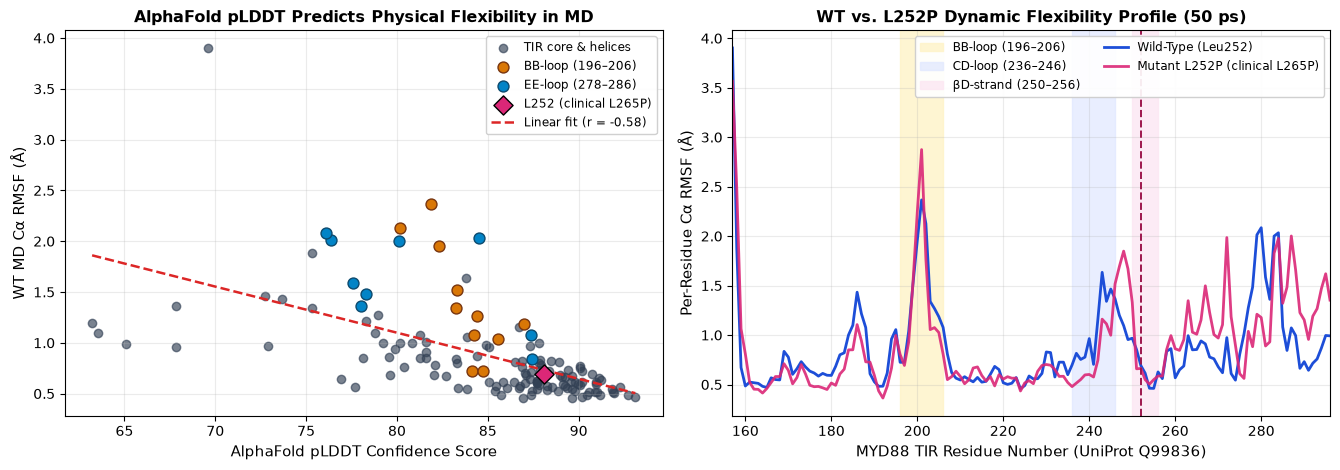

In [5]:
# Load both 50 ps trajectories into memory and superpose all frames onto Cα backbone
u_wt = mda.Universe(tir_wt_md_pdb, tir_wt_dcd)
u_mu = mda.Universe(tir_mut_md_pdb, tir_mut_dcd)

u_wt.transfer_to_memory()
u_mu.transfer_to_memory()

align.AlignTraj(u_wt, u_wt, select="name CA", in_memory=True).run()
align.AlignTraj(u_mu, u_mu, select="name CA", in_memory=True).run()

ca_wt = u_wt.select_atoms("name CA")
ca_mu = u_mu.select_atoms("name CA")

tir_resids = ca_wt.resids.astype(int)
tir_plddt  = ca_wt.tempfactors.copy()

rmsf_wt = rms.RMSF(ca_wt).run().results.rmsf
rmsf_mu = rms.RMSF(ca_mu).run().results.rmsf

# Correlation between AlphaFold pLDDT and real MD flexibility
r_pearson = float(np.corrcoef(tir_plddt, rmsf_wt)[0, 1])
print(f"WT MYD88 TIR   — mean Cα RMSF: {rmsf_wt.mean():.2f} Å | max: {rmsf_wt.max():.2f} Å")
print(f"L252P Mutant   — mean Cα RMSF: {rmsf_mu.mean():.2f} Å | max: {rmsf_mu.max():.2f} Å")
print(f"Pearson correlation r(AlphaFold pLDDT, WT MD RMSF) = {r_pearson:.3f}  (higher confidence → lower motion!)")

for region, lo, hi in [
    ("BB-loop (assembly switch)", 196, 206),
    ("CD-loop (interstrand)",     236, 246),
    ("βD-strand (contains L252)", 250, 256),
    ("EE-loop (intrastrand)",     278, 286),
]:
    m = (tir_resids >= lo) & (tir_resids <= hi)
    print(f"  {region:<27s} ({lo}–{hi}): WT = {rmsf_wt[m].mean():.2f} Å | L252P = {rmsf_mu[m].mean():.2f} Å")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Left: AlphaFold pLDDT vs WT MD RMSF scatter
bb_m = (tir_resids >= 196) & (tir_resids <= 206)
ee_m = (tir_resids >= 278) & (tir_resids <= 286)
core_m = ~(bb_m | ee_m)

ax1.scatter(tir_plddt[core_m], rmsf_wt[core_m], color="#334155", alpha=0.65, s=36, label="TIR core & helices")
ax1.scatter(tir_plddt[bb_m],   rmsf_wt[bb_m],   color="#d97706", edgecolor="#78350f", s=62, zorder=5, label="BB-loop (196–206)")
ax1.scatter(tir_plddt[ee_m],   rmsf_wt[ee_m],   color="#0284c7", edgecolor="#0c4a6e", s=62, zorder=5, label="EE-loop (278–286)")
idx_252 = int(np.where(tir_resids == 252)[0][0])
ax1.scatter([tir_plddt[idx_252]], [rmsf_wt[idx_252]], color="#db2777", edgecolor="black", s=95, marker="D", zorder=6, label="L252 (clinical L265P)")

# Linear trendline
slope, intercept = np.polyfit(tir_plddt, rmsf_wt, 1)
x_line = np.linspace(tir_plddt.min(), tir_plddt.max(), 100)
ax1.plot(x_line, slope * x_line + intercept, color="#dc2626", linestyle="--", linewidth=1.8, label=f"Linear fit (r = {r_pearson:.2f})")

ax1.set_xlabel("AlphaFold pLDDT Confidence Score", fontsize=11)
ax1.set_ylabel("WT MD Cα RMSF (Å)", fontsize=11)
ax1.set_title("AlphaFold pLDDT Predicts Physical Flexibility in MD", fontsize=11.5, fontweight="bold")
ax1.legend(loc="upper right", fontsize=8.5, framealpha=0.92)
ax1.grid(alpha=0.25)

# Right: Per-residue RMSF comparison WT vs L252P
ax2.axvspan(196, 206, color="#fef3c7", alpha=0.8, label="BB-loop (196–206)")
ax2.axvspan(236, 246, color="#e0e7ff", alpha=0.7, label="CD-loop (236–246)")
ax2.axvspan(250, 256, color="#fce7f3", alpha=0.8, label="βD-strand (250–256)")
ax2.plot(tir_resids, rmsf_wt, color="#1d4ed8", linewidth=2.0, label="Wild-Type (Leu252)")
ax2.plot(tir_resids, rmsf_mu, color="#db2777", linewidth=2.0, linestyle="-", alpha=0.9, label="Mutant L252P (clinical L265P)")
ax2.axvline(252, color="#9d174d", linestyle="--", linewidth=1.4)
ax2.set_xlim(157, 296)
ax2.set_xlabel("MYD88 TIR Residue Number (UniProt Q99836)", fontsize=11)
ax2.set_ylabel("Per-Residue Cα RMSF (Å)", fontsize=11)
ax2.set_title("WT vs. L252P Dynamic Flexibility Profile (50 ps)", fontsize=11.5, fontweight="bold")
ax2.legend(loc="upper right", fontsize=8.5, framealpha=0.92, ncol=2)
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Step 6: Trajectory Analysis 2 — Backbone Kink at Position 252 (Ramachandran $\phi$ vs. $\psi$) & Global RMSD

Why is substituting **Leucine → Proline** at position 252 so structurally disruptive?
Because Proline's cyclic ring covalently locks its backbone **$\phi$ dihedral angle** near **$\phi \approx -63^\circ$**!

Let's measure:
1. **Left panel:** Global $C_\alpha$ **RMSD over time** (WT vs. L252P) across the 50 ps trajectory.
2. **Right panel:** The exact **Ramachandran $(\phi, \psi)$ trace** of **residue 252** (`Leu252` in WT vs. `Pro252` in L252P) across all 50 frames — watch how **Proline** pins the backbone into a completely different $(\phi, \psi)$ conformational cluster!

WT Leu252  mean (φ, ψ): (-101.7°, +135.9°)  SD = (14.4°, 9.5°)
L252P Pro  mean (φ, ψ): ( -79.0°, +149.3°)  SD = (12.8°, 11.9°)


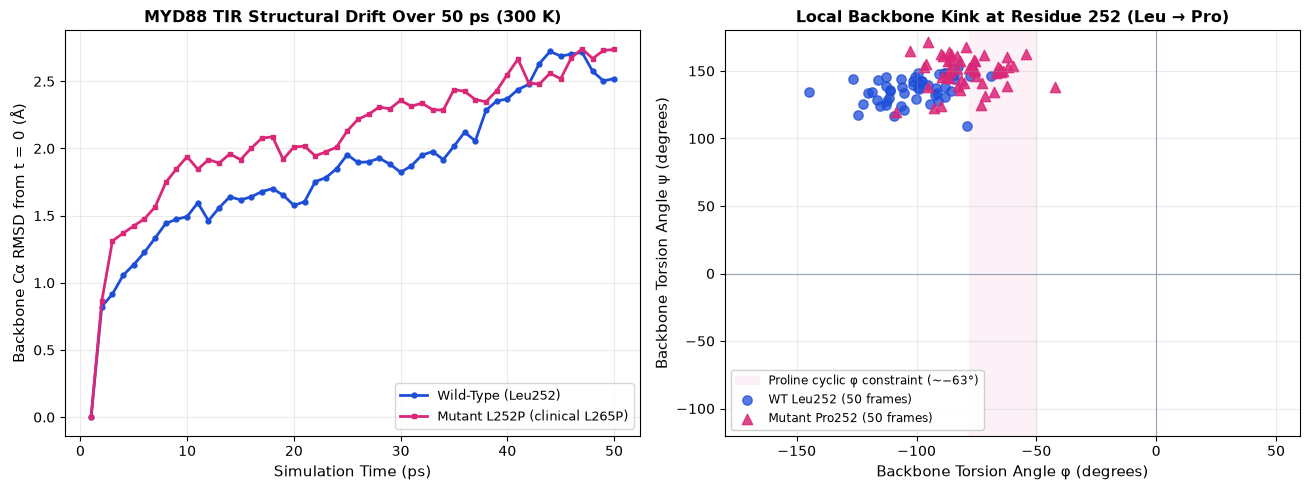

In [6]:
# 1. Global Cα RMSD vs frame 0
rmsd_wt = rms.RMSD(u_wt, u_wt, select="name CA", ref_frame=0).run().results.rmsd[:, 2]
rmsd_mu = rms.RMSD(u_mu, u_mu, select="name CA", ref_frame=0).run().results.rmsd[:, 2]
times_ps = np.linspace(1, 50, len(rmsd_wt))

# 2. Per-frame Ramachandran (phi, psi) at residue 252 (Leu252 vs Pro252)
rama_wt_252 = dihedrals.Ramachandran(u_wt.select_atoms("resid 252")).run().results.angles[:, 0, :]
rama_mu_252 = dihedrals.Ramachandran(u_mu.select_atoms("resid 252")).run().results.angles[:, 0, :]

print(f"WT Leu252  mean (φ, ψ): ({rama_wt_252[:, 0].mean():+6.1f}°, {rama_wt_252[:, 1].mean():+6.1f}°)  SD = ({rama_wt_252[:, 0].std():.1f}°, {rama_wt_252[:, 1].std():.1f}°)")
print(f"L252P Pro  mean (φ, ψ): ({rama_mu_252[:, 0].mean():+6.1f}°, {rama_mu_252[:, 1].mean():+6.1f}°)  SD = ({rama_mu_252[:, 0].std():.1f}°, {rama_mu_252[:, 1].std():.1f}°)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 5.0))

# Left: Global Cα RMSD over time
ax1.plot(times_ps, rmsd_wt, "-o", color="#1d4ed8", markersize=3.5, linewidth=2.0, label="Wild-Type (Leu252)")
ax1.plot(times_ps, rmsd_mu, "-s", color="#db2777", markersize=3.5, linewidth=2.0, label="Mutant L252P (clinical L265P)")
ax1.set_xlabel("Simulation Time (ps)", fontsize=11)
ax1.set_ylabel("Backbone Cα RMSD from t = 0 (Å)", fontsize=11)
ax1.set_title("MYD88 TIR Structural Drift Over 50 ps (300 K)", fontsize=11.5, fontweight="bold")
ax1.legend(loc="lower right", fontsize=9.5)
ax1.grid(alpha=0.25)

# Right: Residue 252 Ramachandran comparison
ax2.axhline(0, color="#94a3b8", linewidth=0.8)
ax2.axvline(0, color="#94a3b8", linewidth=0.8)
ax2.axvspan(-78, -50, color="#fce7f3", alpha=0.55, label="Proline cyclic φ constraint (~−63°)")
ax2.scatter(rama_wt_252[:, 0], rama_wt_252[:, 1], color="#1d4ed8", alpha=0.75, s=45, label="WT Leu252 (50 frames)")
ax2.scatter(rama_mu_252[:, 0], rama_mu_252[:, 1], color="#db2777", marker="^", alpha=0.85, s=55, label="Mutant Pro252 (50 frames)")
ax2.set_xlim(-180, 60)
ax2.set_ylim(-120, 180)
ax2.set_xlabel("Backbone Torsion Angle φ (degrees)", fontsize=11)
ax2.set_ylabel("Backbone Torsion Angle ψ (degrees)", fontsize=11)
ax2.set_title("Local Backbone Kink at Residue 252 (Leu → Pro)", fontsize=11.5, fontweight="bold")
ax2.legend(loc="lower left", fontsize=8.5, framealpha=0.92)
ax2.grid(alpha=0.25)

plt.tight_layout()
plt.show()

---

## Bonus Challenges & SSC Assessment Project Ideas

Now that you have a complete **AlphaFold → AlphaMissense → OpenMM MD** clinical variant pipeline running in Python, try one of these systematic investigations for your **SSC assessment project**:

1. **Compare Recurrent Lymphoma & Immunodeficiency Mutations in MYD88 (Step 3):**
   - Run **L252P** (Waldenström / DLBCL, `0.997`), **M219T** (`M232T` in the exact same pocket, `0.978`), **R196C** (BB-loop loss-of-function immunodeficiency, `0.983`), and conservative **L252I** (`0.435`).
   - How do their local pockets, AlphaMissense scores, and backbone $(\phi, \psi)$ angles differ?
2. **Test the Sickle-Cell Surface Mutation *In Silico*:**
   - Call `mutate_structure("data/alphafold/AF-P68871-F1-model_v6.pdb", resid=7, new_aa="V")` to build **HbS (E6V / E7V)** and relax it in OpenMM. Why does this lethal mutation barely disturb the monomer's fold?
3. **Thermal Stress Sweep:**
   - Re-run Step 3 at **`TEMPERATURE = 150`** vs **`300`** vs **`450`** K. How does temperature amplify local flexibility around the mutation site?
4. **Connect Across Scales into Week 4 (From Atoms to Blood Cancer Drugs!):**
   - In [**Week 4: Cell Signalling Modelling — NF-κB in Blood Cancer**](../signalling/01-nfkb-and-systems-biology.md) and [**4.3 Drug Discovery for Waldenström Macroglobulinemia**](../signalling/03-waldenstrom-drug-discovery.ipynb), you will turn on this **exact MYD88 L265P mutation** (`k1_MYD88SELFACTIVATION-TLR = 1.0`) in a 140-species virtual B-cell and screen targeted lymphoma drugs!
   - *Multi-scale synthesis:* Explaining how **one Leu→Pro atomic kink in the βD-strand** drives **TIR–TIR oligomerisation**, which turns on **constitutive NF-κB signalling** in a B-cell, makes an outstanding 6-minute SSC presentation!